# Stage 2: chronological calibration of frozen compact models

Read saved outputs only: no model loading, inference, fitting, recalibration or table writes. These are reused retrospective development periods with batch-month label availability. No November–December results are used.

The full report is `reports/chronological_calibration_study.md`.

In [1]:
from pathlib import Path
import json
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
ROOT=Path.cwd()
if not (ROOT/'experiments/calibration_study').exists(): ROOT=ROOT.parent
OUT=ROOT/'outputs/experiments/calibration_study/stage2_calibration_001'
m=pd.read_csv(OUT/'monthly_metrics.csv')
comparisons=pd.read_csv(OUT/'monthly_comparisons.csv')
params=pd.DataFrame(json.loads((OUT/'calibration_parameters.json').read_text()))
print('Run:',OUT.name)
display(params[['comparison','base','base_fit_last_date','calibration_first_date','calibration_last_date','intercept','prevalence','calibrated_mean']])
display(pd.read_csv(OUT/'score_provenance.csv'))

Matplotlib is building the font cache; this may take a moment.


Run: stage2_calibration_001


,comparison,base,base_fit_last_date,calibration_first_date,calibration_last_date,intercept,prevalence,calibrated_mean
0,1,F,2013-03-31,2013-04-01,2013-04-30,0.134458,0.231545,0.231545
1,1,G,2013-03-31,2013-04-01,2013-04-30,0.136699,0.231545,0.231545
2,2,F,2013-04-30,2013-05-01,2013-05-31,0.101550,0.235363,0.235363
3,2,G,2013-04-30,2013-05-01,2013-05-31,0.092770,0.235363,0.235363
4,3,F,2013-05-31,2013-06-01,2013-06-30,0.473107,0.294338,0.294338
5,3,G,2013-05-31,2013-06-01,2013-06-30,0.478068,0.294338,0.294338
6,4,F,2013-07-31,2013-08-01,2013-08-31,-0.091539,0.228564,0.228564
7,4,G,2013-07-31,2013-08-01,2013-08-31,-0.120693,0.228564,0.228564


,comparison,base,period,first_date,last_date,reused_n,generated_n
0,1,F,calibration,2013-04-01,2013-04-30,27662,0
1,1,F,threshold,2013-05-01,2013-05-31,28233,0
2,1,F,assessment,2013-06-01,2013-06-30,0,27234
3,1,G,calibration,2013-04-01,2013-04-30,27662,0
4,1,G,threshold,2013-05-01,2013-05-31,28233,0
5,1,G,assessment,2013-06-01,2013-06-30,0,27234
6,2,F,calibration,2013-05-01,2013-05-31,28233,0
7,2,F,threshold,2013-06-01,2013-06-30,27234,0
8,2,F,assessment,2013-07-01,2013-08-31,0,57326
9,2,G,calibration,2013-05-01,2013-05-31,28233,0


## Future probability levels and primary loss outcomes
Every cell compares the same flights and frozen base pipeline. Negative calibrated-minus-raw losses favor calibration. Repeated August assessments are not independent evidence.

,comparison,base,month,raw_prevalence,raw_mean_probability,raw_brier,raw_log_loss,raw_f1,raw_roc_auc,raw_average_precision,cal_mean_probability,cal_brier,cal_log_loss,cal_f1,cal_roc_auc,cal_average_precision
0,1,F,6,0.294338,0.205601,0.198525,0.582457,0.524648,0.693270,0.448951,0.226637,0.194771,0.571925,0.523023,0.693270,0.448951
1,1,G,6,0.294338,0.205862,0.197247,0.579939,0.513031,0.695325,0.454246,0.227068,0.193520,0.569278,0.511269,0.695325,0.454246
2,2,F,7,0.303282,0.213765,0.201574,0.590547,0.529881,0.689841,0.460811,0.229841,0.198656,0.582267,0.531143,0.689841,0.460811
3,2,F,8,0.228564,0.215669,0.164496,0.502045,0.444883,0.685569,0.360448,0.231814,0.164354,0.501549,0.441095,0.685569,0.360448
4,2,G,7,0.303282,0.214128,0.201014,0.590080,0.529742,0.690204,0.461918,0.228632,0.198421,0.582477,0.529006,0.690204,0.461918
5,2,G,8,0.228564,0.215923,0.163450,0.499527,0.445076,0.688914,0.371136,0.230490,0.163365,0.499026,0.441081,0.688914,0.371136
6,3,F,8,0.228564,0.218657,0.163342,0.498809,0.448574,0.692035,0.367753,0.300473,0.168882,0.512861,0.448101,0.692035,0.367753
7,3,G,8,0.228564,0.217684,0.161963,0.495112,0.442966,0.698506,0.379762,0.299317,0.167547,0.508811,0.450780,0.698506,0.379762
8,4,F,10,0.154469,0.244180,0.131533,0.424581,0.361414,0.699763,0.283118,0.229202,0.128692,0.417059,0.365524,0.699763,0.283118
9,4,G,10,0.154469,0.245071,0.130654,0.421248,0.365308,0.707466,0.305724,0.225520,0.126915,0.411503,0.364340,0.707466,0.305724


,comparison,base,method,month,n,prevalence,mean_probability,mean_prediction_error,brier,log_loss,roc_auc,average_precision
0,1,F,calibration_prior,6,27234,0.294338,0.231545,-0.062793,0.211646,0.616463,0.500000,0.294338
1,1,F,intercept,6,27234,0.294338,0.226637,-0.067701,0.194771,0.571925,0.693270,0.448951
2,1,F,raw,6,27234,0.294338,0.205601,-0.088737,0.198525,0.582457,0.693270,0.448951
3,1,F,training_prior,6,27234,0.294338,0.210734,-0.083604,0.214693,0.625327,0.500000,0.294338
4,1,G,calibration_prior,6,27234,0.294338,0.231545,-0.062793,0.211646,0.616463,0.500000,0.294338
5,1,G,intercept,6,27234,0.294338,0.227068,-0.067270,0.193520,0.569278,0.695325,0.454246
6,1,G,raw,6,27234,0.294338,0.205862,-0.088476,0.197247,0.579939,0.695325,0.454246
7,1,G,training_prior,6,27234,0.294338,0.210734,-0.083604,0.214693,0.625327,0.500000,0.294338
8,2,F,calibration_prior,7,28485,0.303282,0.235363,-0.067920,0.215915,0.625703,0.500000,0.303282
9,2,F,calibration_prior,8,28841,0.228564,0.235363,0.006799,0.176368,0.537664,0.500000,0.228564


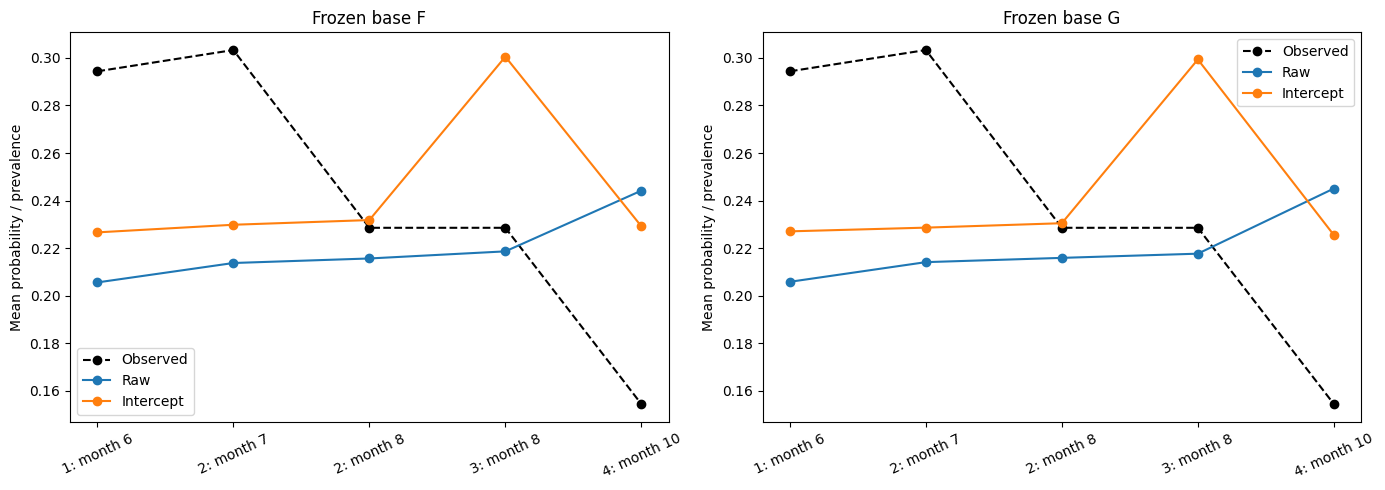

In [2]:
display(comparisons)
display(m[['comparison','base','method','month','n','prevalence','mean_probability','mean_prediction_error','brier','log_loss','roc_auc','average_precision']])
fig,axes=plt.subplots(1,2,figsize=(14,5))
for ax,base in zip(axes,['F','G']):
    g=comparisons.loc[comparisons.base.eq(base)]
    x=range(len(g));labels=[f'{r.comparison}: month {r.month}' for r in g.itertuples()]
    ax.plot(x,g.raw_prevalence,'k--o',label='Observed')
    ax.plot(x,g.raw_mean_probability,'o-',label='Raw')
    ax.plot(x,g.cal_mean_probability,'o-',label='Intercept')
    ax.set(title=f'Frozen base {base}',xticks=list(x),xticklabels=labels,ylabel='Mean probability / prevalence')
    ax.tick_params(axis='x',rotation=25);ax.legend()
plt.tight_layout();plt.show()

## Reliability and bin counts
Intercept fitting matches the calibration-month mean by construction. The diagrams below use later assessment labels; mean agreement and ranking alone do not establish calibrated individual risk.

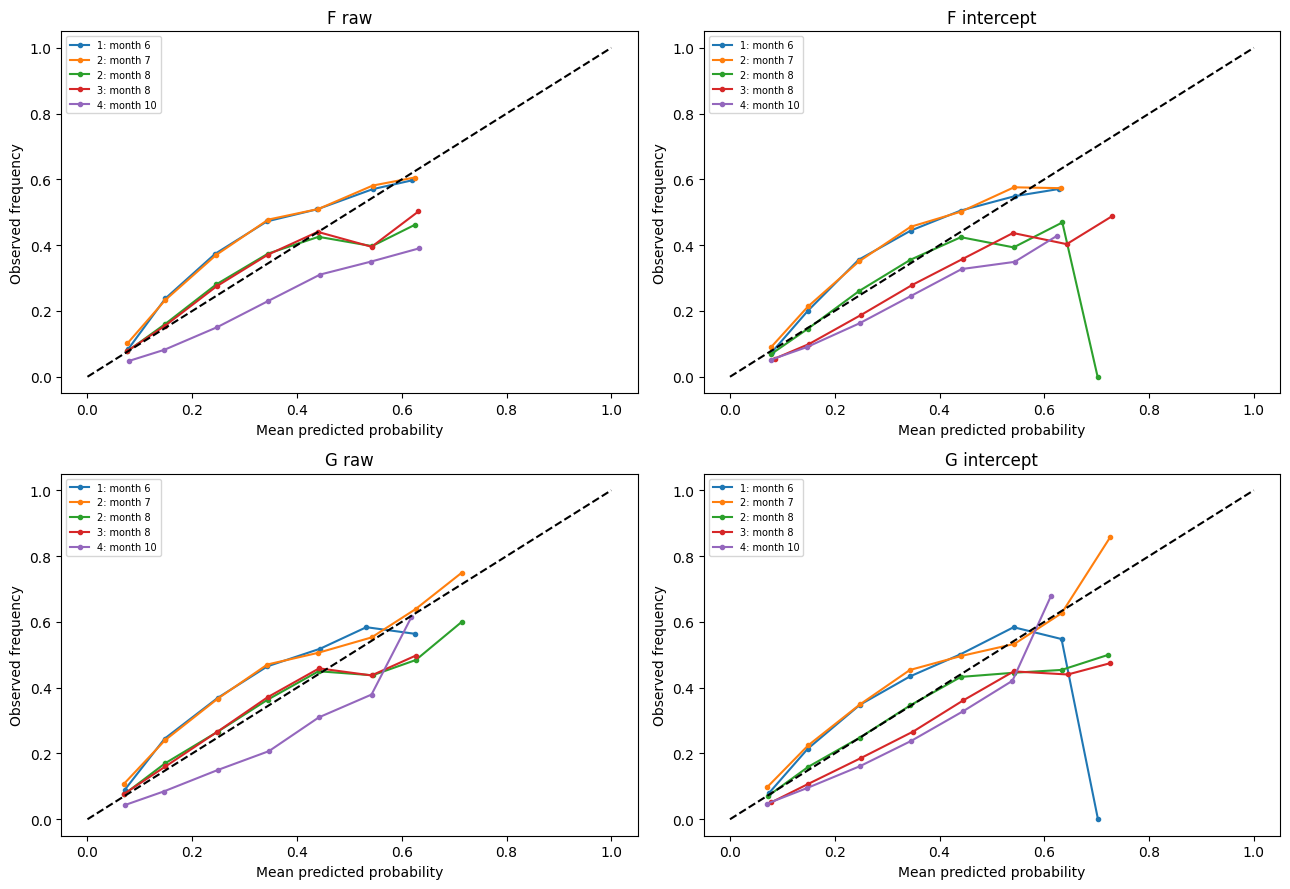

,bin,n,mean_probability,observed_rate,comparison,base,method,month
0,"(0.2, 0.3]",27234,0.231545,0.294338,1,F,calibration_prior,6
1,"(-0.001, 0.1]",3286,0.080923,0.076385,1,F,intercept,6
2,"(0.1, 0.2]",9747,0.148671,0.200575,1,F,intercept,6
3,"(0.2, 0.3]",7722,0.245703,0.355737,1,F,intercept,6
4,"(0.3, 0.4]",4060,0.345083,0.444335,1,F,intercept,6
...,...,...,...,...,...,...,...,...
163,"(0.3, 0.4]",5425,0.346487,0.207189,4,G,raw,10
164,"(0.4, 0.5]",2880,0.441647,0.309722,4,G,raw,10
165,"(0.5, 0.6]",1319,0.542250,0.379075,4,G,raw,10
166,"(0.6, 0.7]",140,0.618286,0.614286,4,G,raw,10


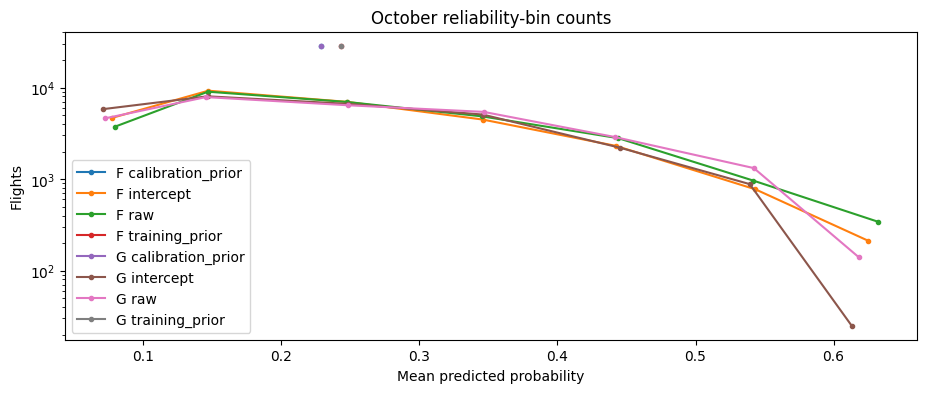

In [3]:
bins=pd.read_csv(OUT/'monthly_reliability.csv')
fig,axes=plt.subplots(2,2,figsize=(13,9))
for row,base in enumerate(['F','G']):
    for col,method in enumerate(['raw','intercept']):
        ax=axes[row,col]
        for (comparison,month),g in bins.loc[bins.base.eq(base)&bins.method.eq(method)].groupby(['comparison','month']):
            ax.plot(g.mean_probability,g.observed_rate,'.-',label=f'{comparison}: month {month}')
        ax.plot([0,1],[0,1],'k--');ax.set(title=f'{base} {method}',xlabel='Mean predicted probability',ylabel='Observed frequency');ax.legend(fontsize=7)
plt.tight_layout();plt.show()
display(bins)
# Counts remain visible rather than treating sparse high-risk bins as equally reliable.
fig,ax=plt.subplots(figsize=(11,4))
for (base,method),g in bins.loc[bins.comparison.eq(4)].groupby(['base','method']):
    ax.plot(g.mean_probability,g.n,'.-',label=f'{base} {method}')
ax.set(title='October reliability-bin counts',xlabel='Mean predicted probability',ylabel='Flights',yscale='log');ax.legend();plt.show()

## Classification is an operating-point diagnostic
Separate raw/calibrated thresholds come only from their designated earlier threshold month. Offsetting cannot improve ranking; a changed F1 on the fixed numeric grid is an operating-point effect. Corresponding transformed thresholds should preserve classifications.

In [4]:
display(pd.read_csv(OUT/'selected_thresholds.csv'))
display(m.loc[m.method.isin(['raw','intercept']),['comparison','base','method','month','threshold','precision','recall','f1','accuracy','tn','fp','fn','tp']])
display(pd.read_csv(OUT/'equivalent_thresholds.csv'))
print('Maximum absolute AUC/AP differences:')
diff=pd.read_csv(OUT/'monthly_differences.csv')
display(diff[['roc_auc_calibrated_minus_raw','average_precision_calibrated_minus_raw']].abs().max())

,comparison,base,method,threshold
0,1,F,raw,0.175
1,1,F,intercept,0.200
2,1,G,raw,0.200
3,1,G,intercept,0.225
4,2,F,raw,0.175
5,2,F,intercept,0.175
6,2,G,raw,0.175
7,2,G,intercept,0.175
8,3,F,raw,0.175
9,3,F,intercept,0.250


,comparison,base,method,month,threshold,precision,recall,f1,accuracy,tn,fp,fn,tp
1,1,F,intercept,6,0.200,0.409126,0.724800,0.523023,0.610891,10827,8391,2206,5810
2,1,F,raw,6,0.175,0.405928,0.741517,0.524648,0.604502,10519,8699,2072,5944
5,1,G,intercept,6,0.225,0.422152,0.648079,0.511269,0.635309,12107,7111,2821,5195
6,1,G,raw,6,0.200,0.421874,0.654441,0.513031,0.634317,12029,7189,2770,5246
10,2,F,intercept,7,0.175,0.398265,0.797083,0.531143,0.573214,9442,10404,1753,6886
11,2,F,intercept,8,0.175,0.303035,0.810225,0.441095,0.530703,9965,12284,1251,5341
12,2,F,raw,7,0.175,0.408666,0.753328,0.529881,0.594594,10429,9417,2131,6508
13,2,F,raw,8,0.175,0.312777,0.770176,0.444883,0.560695,11094,11155,1515,5077
18,2,G,intercept,7,0.175,0.400907,0.777405,0.529006,0.580165,9810,10036,1923,6716
19,2,G,intercept,8,0.175,0.305424,0.793538,0.441081,0.540342,10353,11896,1361,5231


,comparison,base,month,raw_threshold,mapped_threshold,n,mismatches,boundary_rows,nonboundary_mismatches,boundary_tolerance
0,1,F,6,0.175,0.195267,27234,0,0,0,1.000000e-12
1,1,G,6,0.200,0.222770,27234,0,0,0,1.000000e-12
2,2,F,7,0.175,0.190148,28485,0,0,0,1.000000e-12
3,2,F,8,0.175,0.190148,28841,0,0,0,1.000000e-12
4,2,G,7,0.175,0.188800,28485,0,0,0,1.000000e-12
5,2,G,8,0.175,0.188800,28841,0,0,0,1.000000e-12
6,3,F,8,0.175,0.253981,28841,0,0,0,1.000000e-12
7,3,G,8,0.150,0.221571,28841,0,0,0,1.000000e-12
8,4,F,10,0.250,0.233232,28653,0,0,0,1.000000e-12
9,4,G,10,0.275,0.251601,28653,0,0,0,1.000000e-12


Maximum absolute AUC/AP differences:


roc_auc_calibrated_minus_raw              0.0
average_precision_calibrated_minus_raw    0.0
dtype: float64

## Paired uncertainty
500 seven-calendar-day moving-block replicates, fixed fitted scores/intercepts. Intervals do not account for all temporal dependence, overlapping periods or prior selection. Comparison 2 pooled intervals are only a within-comparison diagnostic.

,metric,difference,ci_low,ci_high,replicates,seed,scheme,comparison,base,assessment_scope
0,brier,-0.003755,-0.006352,-0.001058,500,42,paired seven-calendar-day moving blocks,1,F,6
1,log_loss,-0.010533,-0.017613,-0.003104,500,42,paired seven-calendar-day moving blocks,1,F,6
2,brier,-0.003728,-0.006360,-0.000983,500,42,paired seven-calendar-day moving blocks,1,G,6
3,log_loss,-0.010661,-0.017883,-0.003141,500,42,paired seven-calendar-day moving blocks,1,G,6
4,brier,-0.002918,-0.004689,-0.001661,500,42,paired seven-calendar-day moving blocks,2,F,7
5,log_loss,-0.008281,-0.012964,-0.004801,500,42,paired seven-calendar-day moving blocks,2,F,7
6,brier,-0.000141,-0.001750,0.001284,500,42,paired seven-calendar-day moving blocks,2,F,8
7,log_loss,-0.000496,-0.004564,0.003050,500,42,paired seven-calendar-day moving blocks,2,F,8
8,brier,-0.001521,-0.002814,0.000006,500,42,paired seven-calendar-day moving blocks,2,F,combined_within_comparison
9,log_loss,-0.004364,-0.007866,-0.000327,500,42,paired seven-calendar-day moving blocks,2,F,combined_within_comparison


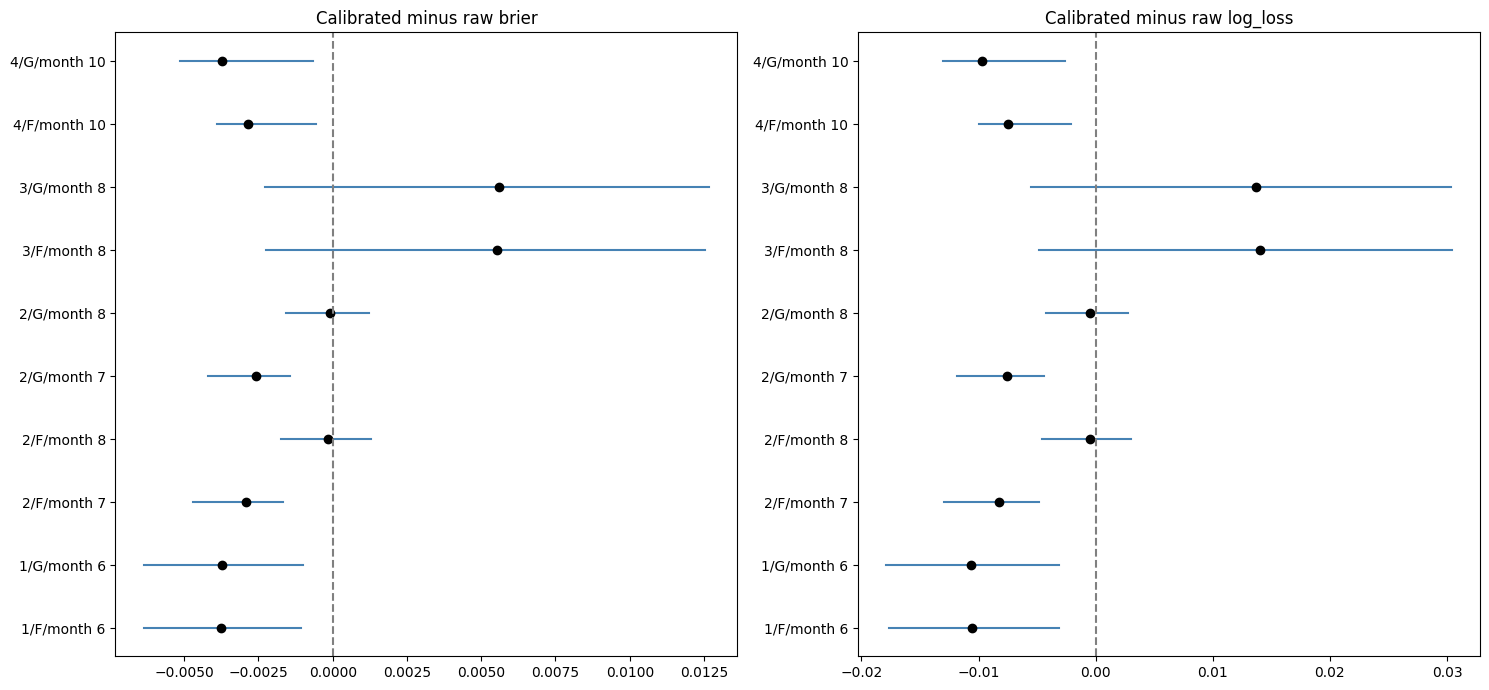

In [5]:
intervals=pd.read_csv(OUT/'paired_block_intervals.csv')
display(intervals)
monthly=intervals.loc[intervals.assessment_scope.ne('combined_within_comparison')]
fig,axes=plt.subplots(1,2,figsize=(15,7))
for ax,metric in zip(axes,['brier','log_loss']):
    g=monthly.loc[monthly.metric.eq(metric)].reset_index(drop=True)
    labels=[f'{r.comparison}/{r.base}/month {r.assessment_scope}' for r in g.itertuples()]
    for i,r in g.iterrows():
        ax.plot([r.ci_low,r.ci_high],[i,i],color='steelblue');ax.plot(r.difference,i,'ko')
    ax.axvline(0,color='gray',linestyle='--');ax.set(title=f'Calibrated minus raw {metric}',yticks=range(len(g)),yticklabels=labels)
plt.tight_layout();plt.show()

## Review boundary
Read the report’s recommendation across all periods. No production model, Stage 1 artifact or previous finding is modified. No universal calibration rule or real-time deployment claim follows from these reused comparisons.

In [6]:
display(pd.read_csv(OUT/'base_integrity.csv')[['comparison','base','unchanged','base_fit_calls']])
print('This notebook reads saved outputs only. No model inference or fitting was performed.')

,comparison,base,unchanged,base_fit_calls
0,1,F,True,0
1,1,G,True,0
2,2,F,True,0
3,2,G,True,0
4,3,F,True,0
5,3,G,True,0
6,4,F,True,0
7,4,G,True,0


This notebook reads saved outputs only. No model inference or fitting was performed.
